### Make temporary directory

In [1]:
import os, random, string

In [2]:
cwd = os.path.basename(os.getcwd())
tmpdir = os.path.join("/flash/ReiterU/tmp/", 'tomo_' + ''.join(random.choices(string.ascii_uppercase, k=12)))
print(tmpdir)
if not os.path.exists(tmpdir):
    os.makedirs(tmpdir)

/flash/ReiterU/tmp/tomo_WGCCMVJKTXTO


### Main

In [3]:
import numpy as np
import pandas as pd
import h5py
from matplotlib import pyplot as plt
from scipy import ndimage as ndi
from scipy.signal import find_peaks, peak_prominences
from roifile import roiread
from skimage import draw
import cv2

from scipy.signal import butter, filtfilt
from sklearn.metrics import pairwise_distances
from scipy.cluster.hierarchy import linkage, leaves_list
import subprocess

In [4]:
from matplotlib import font_manager
import matplotlib as mpl
font_manager.fontManager.addfont('/bucket/ReiterU/common/fonts/arial.ttf')
mpl.rcParams.update({
    'font.size': 7,
    'axes.titlesize': 7,
    'legend.fontsize': 7,
    'font.family': 'sans-serif',
    'font.sans-serif': "Arial",
    'pdf.fonttype': 42,
    'ps.fonttype': 42,
    'axes.linewidth': 0.5,
    'xtick.major.width': 0.5,
    'xtick.major.size': 2,
    'xtick.minor.size': 2,
    'xtick.minor.width': 0.5,
    'ytick.major.width': 0.5,
    'ytick.minor.width': 0.5,
    'ytick.major.size': 2,
    'ytick.minor.size': 2,
})

### Parameters

In [5]:
dff_ogl = "/bucket/ReiterU/OLdev/experiments/20250523_squid_cal520/2P/rec3/dff/ROI_yutaka_z0/DFF.hdf5"
dff_igl = "/bucket/ReiterU/OLdev/experiments/20250523_squid_cal520/2P/rec3/dff/ROI_yutaka_z3/DFF.hdf5"
bad_frames_npy = "/bucket/ReiterU/OLdev/experiments/20250523_squid_cal520/2P/rec3/mcorr_paired_0_3/QC/bad_frames.npy"
savedir = "/bucket/ReiterU/OLdev/analysis/20250604_OGL_IGL_sponaneous_activity/20250523_rec3"

### Load DF/F

In [6]:
d = []
with h5py.File(dff_ogl) as hf:
    x = hf["dff"][:, ::100] # reduce to 10 Hz
    d.append(x)

with h5py.File(dff_igl) as hf:
    x = hf["dff"][:, ::100] # reduce to 10 Hz
    d.append(x)

print(d[0].shape, d[1].shape)

(132, 18345) (98, 18345)


In [7]:
bad_frames = np.load(bad_frames_npy)

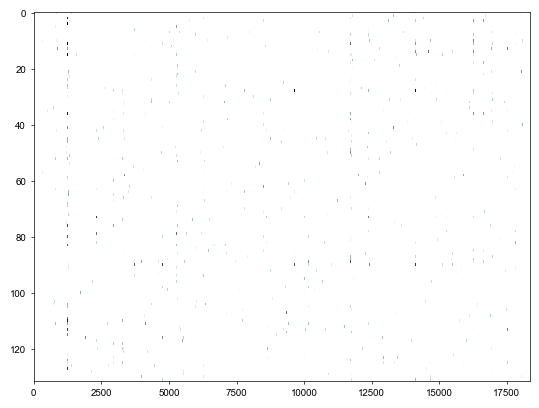

In [8]:
plt.imshow(ndi.gaussian_filter1d(d[0], sigma=3, axis=1), aspect="auto", vmin=2, vmax=4, cmap="bone_r", interpolation="nearest")

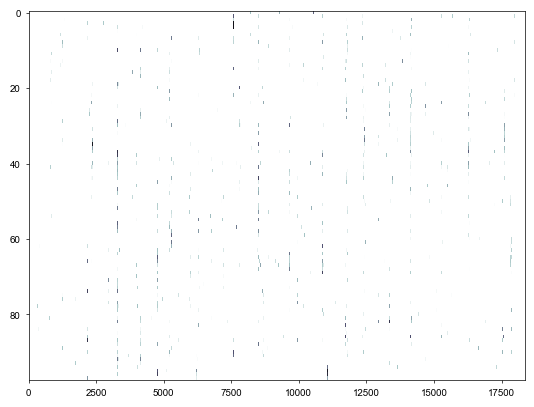

In [9]:
plt.imshow(ndi.gaussian_filter1d(d[1], sigma=3, axis=1), aspect="auto", vmin=2, vmax=4, cmap="bone_r", interpolation="nearest")

### Detect peaks

In [10]:
p = []
p_props = []
show_plot = False

for i in range(2):
    peaks_list = []
    peak_props = []
    for j, trace in enumerate(d[i]):
        trace= ndi.gaussian_filter1d(trace, sigma=3, mode="nearest")
        peaks, properties = find_peaks(trace, height=3, prominence=4., distance=10)
        prominences = peak_prominences(trace, peaks)[0]
        peaks_list.append(peaks)
        peak_props.append(prominences)

        if show_plot:
            print(i, j)
            fig, ax = plt.subplots(figsize=(15,5))
            ax.plot(trace, label='∆F/F')
            ax.plot(peaks, trace[peaks], 'rx', label='Peaks')
            ax.set_ylim(-1, 5)
            plt.show()
    p.append(peaks_list)
    p_props.append(peak_props)

In [11]:
# remove peaks detected during bad_frames

p2 = []
for i in range(2):
    peaks_list = []
    for pk in p[i]:
        cleaned_peaks = []
        for x in pk:
            idx = int(x * 3.75 / 10)
            if not bad_frames[idx]:
                cleaned_peaks.append(x)
        peaks_list.append(cleaned_peaks)
    p2.append(peaks_list)

In [12]:
# def sort_rows_hierarchical(data, method='average', metric='jaccard'):
#     # Compute pairwise distance matrix
#     dist_matrix = pairwise_distances(data, metric=metric)

#     # Perform hierarchical clustering
#     linkage_matrix = linkage(dist_matrix, method=method)

#     # Get the optimal leaf order (row sorting)
#     order = leaves_list(linkage_matrix)

#     return data[order], order

# def sort_rows_by_similarity(data, start_index=0, metric='jaccard'):
#     n_rows = data.shape[0]
#     visited = np.zeros(n_rows, dtype=bool)
#     order = [start_index]
#     visited[start_index] = True

#     # Compute full pairwise distance matrix
#     distances = pairwise_distances(data, metric=metric)

#     for _ in range(n_rows - 1):
#         last = order[-1]
#         # Mask already visited rows
#         dists = distances[last]
#         dists[visited] = np.inf
#         next_index = np.argmin(dists)
#         order.append(next_index)
#         visited[next_index] = True

#     return data[order], order

def show_raster(dff, peaks, figsavename=None):
    raster0 = np.zeros_like(dff[0])
    for (i, k) in enumerate(peaks[0]):
        raster0[i, k] = 1

    raster1 = np.zeros_like(dff[1])
    for (i, k) in enumerate(peaks[1]):
        raster1[i, k] = 1

    r1 = raster0.copy()
    r2 = raster1.copy()
    
    # shuffle rows
    np.random.shuffle(r1)
    np.random.shuffle(r2)
    r1 = r1[0:30]
    r2 = r2[0:30]
    
    # # sort rows by similarity
    # r1, _ = sort_rows_by_similarity(r1,  metric="hamming")
    # r2, _ = sort_rows_by_similarity(r2,  metric="hamming")
    
    fig = plt.figure(figsize=(1.6,2.6), dpi=300)
    gs = fig.add_gridspec(6, 1,
                          height_ratios=[0.5, 1.0, 0.1, 0.5, 1.0, 0.25],
                          wspace=0.1, hspace=0.05)
    
    TIME_RANGE = (150, 750)
    
    time = np.arange(d[0].shape[1]) * 0.1 # 10 Hz
    
    # mean activity of all cells in OGL
    ax = fig.add_subplot(gs[0,0])
    m = np.nanmean(dff[0], axis=0)
    ax.plot(time, m, lw=0.5, color="k")
    ax.set_xticks([])
    ax.set_yticks([])
    ax.set_ylim(-1,3)
    ax.set_xlim(TIME_RANGE)
    for sp in ["top", "right", "bottom", "left"]:
        ax.spines[sp].set_visible(False)
    
    # raster plot of OGL
    ax = fig.add_subplot(gs[1,0])
    spike_times = [np.where(row)[0]*0.1 for row in r1]
    ax.eventplot(spike_times, orientation='horizontal', colors='black',linewidths=0.5)
    # ax.imshow(r1, aspect="auto", vmin=0, vmax=1, cmap="gray_r", interpolation="nearest", extent=(time[0], time[-1], r1.shape[0], 0))
    for sp in ["top", "right", "bottom", "left"]:
        ax.spines[sp].set_visible(False)
    ax.set_xticks([])
    ax.set_yticks([])
    # ax.set_xlim(TIME_RANGE)
    
    # mean activity of all cells in IGL
    ax = fig.add_subplot(gs[3,0])
    m = np.nanmean(dff[1], axis=0)
    ax.plot(time, m, lw=0.5, color="k")
    ax.set_xticks([])
    ax.set_yticks([])
    ax.set_ylim(-1,3)
    for sp in ["top", "right", "bottom", "left"]:
        ax.spines[sp].set_visible(False)
    ax.set_xlim(TIME_RANGE)
    
    # raster plot of OGL
    ax = fig.add_subplot(gs[4,0])
    spike_times = [np.where(row)[0]*0.1 for row in r2]
    ax.eventplot(spike_times, orientation='horizontal', colors='black', linewidths=0.5)
    # ax.imshow(r2, aspect="auto", vmin=0, vmax=1, cmap="gray_r", interpolation="nearest", extent=(time[0], time[-1], r1.shape[0], 0))
    for sp in ["top", "right", "bottom", "left"]:
        ax.spines[sp].set_visible(False)
    ax.set_xticks([])
    ax.set_yticks([])
    ax.set_xlim(TIME_RANGE)
    
    ax = fig.add_subplot(gs[5,0])
    ax.plot([time[0] +TIME_RANGE[0], time[600]+TIME_RANGE[0]], [-0.5,-0.5], color='black', lw=2)
    ax.text(time[300]+TIME_RANGE[0], 0.5, '1 min', color='black', ha='center', va='center', rotation=0)
    ax.set_xlim(TIME_RANGE)
    ax.set_ylim(-1, 1)
    ax.axis("off")

    if figsavename:
        plt.savefig(figsavename)
    plt.show()

/scratch/ipykernel_1882525/2993866434.py:66: RuntimeWarning: Mean of empty slice
  m = np.nanmean(dff[0], axis=0)
/scratch/ipykernel_1882525/2993866434.py:88: RuntimeWarning: Mean of empty slice
  m = np.nanmean(dff[1], axis=0)


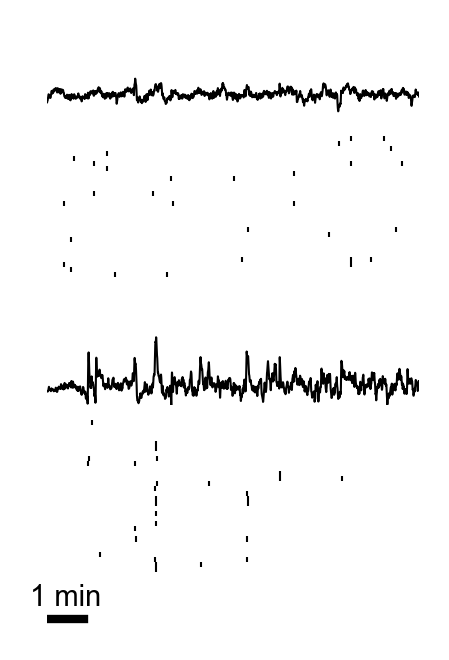

In [13]:
show_raster(d, p2, figsavename=os.path.join(tmpdir, "raster.pdf"))

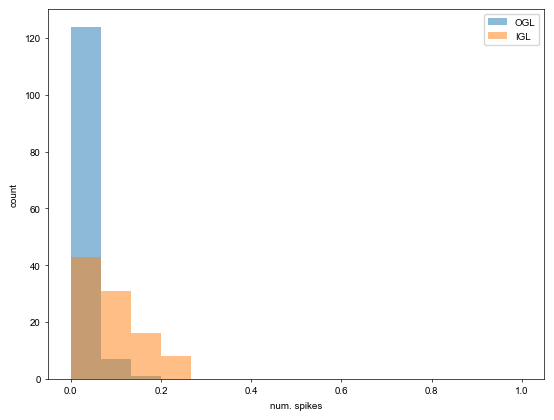

In [14]:
num_peaks1 = np.array([len(e) for e in p2[0]], dtype="float")
num_peaks2 = np.array([len(e) for e in p2[1]], dtype="float")

# spikes per minute
spike_rate1 = num_peaks1 / (d[0].shape[1] * 0.1) * 60
spike_rate2 = num_peaks2 / (d[0].shape[1] * 0.1) * 60

fig, ax = plt.subplots()
ax.hist(spike_rate1, range=[0,1], bins=15, alpha=0.5, label="OGL")
ax.hist(spike_rate2, range=[0,1], bins=15, alpha=0.5, label="IGL")
ax.set_xlabel("num. spikes")
ax.set_ylabel("count")
plt.legend()
plt.show()

In [15]:
num_peaks1

array([1., 0., 0., 1., 0., 1., 1., 0., 1., 0., 2., 1., 0., 2., 3., 0., 2.,
       0., 0., 0., 0., 0., 1., 0., 0., 0., 0., 0., 4., 2., 1., 1., 0., 2.,
       0., 0., 2., 0., 1., 0., 0., 2., 1., 0., 1., 2., 0., 0., 3., 2., 2.,
       0., 1., 1., 0., 0., 1., 0., 2., 0., 1., 0., 1., 1., 1., 0., 0., 1.,
       0., 1., 0., 1., 0., 3., 0., 1., 0., 1., 3., 2., 0., 2., 3., 1., 0.,
       0., 0., 1., 1., 3., 5., 2., 0., 0., 1., 0., 2., 0., 0., 0., 0., 0.,
       0., 2., 2., 0., 0., 2., 1., 0., 1., 2., 0., 2., 1., 0., 0., 0., 0.,
       0., 0., 0., 0., 1., 1., 2., 2., 0., 1., 1., 1., 1.])

In [16]:
num_peaks2

array([5., 4., 1., 2., 1., 3., 3., 2., 1., 0., 3., 0., 2., 2., 4., 7., 0.,
       2., 3., 3., 4., 6., 1., 0., 0., 4., 1., 1., 2., 1., 2., 3., 3., 4.,
       2., 6., 2., 6., 4., 4., 6., 8., 2., 4., 6., 2., 1., 4., 4., 7., 7.,
       5., 5., 2., 3., 4., 6., 2., 6., 1., 2., 2., 4., 0., 6., 2., 8., 8.,
       5., 3., 0., 2., 1., 1., 7., 3., 0., 2., 1., 4., 4., 2., 8., 6., 4.,
       0., 6., 4., 5., 3., 3., 2., 4., 2., 4., 6., 3., 1.])

### Save as CSV

In [17]:
np.savetxt(os.path.join(tmpdir, 'OGL_spike_rate.csv'), spike_rate1, delimiter=',', fmt='%.4f')
np.savetxt(os.path.join(tmpdir, 'IGL_spike_rate.csv'), spike_rate2, delimiter=',', fmt='%.4f')

### Save result to bucket

In [18]:
cmd1 = f'ssh deigo "mkdir -p {savedir}"'
cmd2 = f'ssh deigo "cp -r {tmpdir}/* {savedir}"'
print(cmd1)
print(cmd2)

subprocess.run(cmd1, shell=True, check=True)
subprocess.run(cmd2, shell=True, check=True)

ssh deigo "mkdir -p /bucket/ReiterU/OLdev/analysis/20250604_OGL_IGL_sponaneous_activity/20250523_rec3"
ssh deigo "cp -r /flash/ReiterU/tmp/tomo_WGCCMVJKTXTO/* /bucket/ReiterU/OLdev/analysis/20250604_OGL_IGL_sponaneous_activity/20250523_rec3"


Offending key for IP in /home/t/tomoyuki-mano1/.ssh/known_hosts:1
Matching host key in /home/t/tomoyuki-mano1/.ssh/known_hosts:6
Offending key for IP in /home/t/tomoyuki-mano1/.ssh/known_hosts:1
Matching host key in /home/t/tomoyuki-mano1/.ssh/known_hosts:6


CompletedProcess(args='ssh deigo "cp -r /flash/ReiterU/tmp/tomo_WGCCMVJKTXTO/* /bucket/ReiterU/OLdev/analysis/20250604_OGL_IGL_sponaneous_activity/20250523_rec3"', returncode=0)